# Task 1: Data Analysis Report

## Problem Statement

The objective of this project is to predict whether a loan applicant is likely to experience payment difficulties.

Using applicant information, financial details and machine learning techniques, the project aims to identify potential default risk and understand the factors influencing repayment difficulties.

In [1]:

# Import necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the main dataset

df = pd.read_csv('application_train.csv')

# Display the first 5 rows

df.head()


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [2]:

# Check number of rows and columns

print("Dataset Shape:", df.shape)

# Check column names

print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values

print("\nDataset Information:")
df.info()

# Statistical summary

df.describe()


Dataset Shape: (307511, 122)

Column Names:
['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [3]:

# Check target variable distribution

print(df['TARGET'].value_counts())

# Check percentage distribution

print("\nPercentage Distribution:")
print(df['TARGET'].value_counts(normalize=True) * 100)


TARGET
0    282686
1     24825
Name: count, dtype: int64

Percentage Distribution:
TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


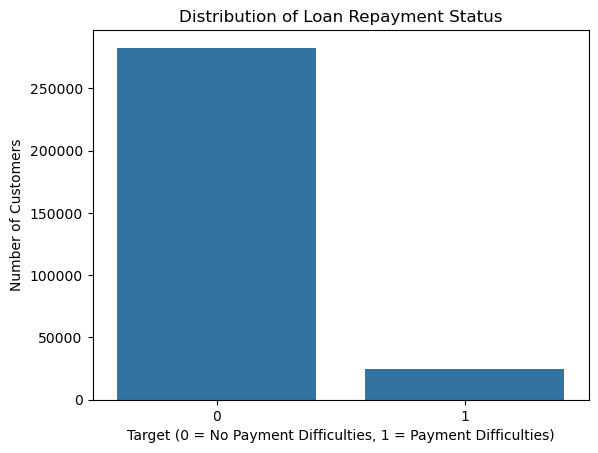

In [4]:

sns.countplot(x='TARGET', data=df)

plt.title('Distribution of Loan Repayment Status')
plt.xlabel('Target (0 = No Payment Difficulties, 1 = Payment Difficulties)')
plt.ylabel('Number of Customers')

plt.show()


In [5]:

# Count missing values in each column

missing_values = df.isnull().sum()

# Calculate missing value percentage

missing_percentage = (df.isnull().mean() * 100)

# Create a summary table

missing_df = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

# Display columns having missing values

missing_df = missing_df[missing_df['Missing Values'] > 0]

missing_df = missing_df.sort_values(
    by='Missing Percentage',
    ascending=False
)

missing_df.head(30)


,Missing Values,Missing Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953


In [6]:

# Total columns containing missing values

print("Columns with missing values:",
      df.isnull().any().sum())

# Columns with more than 50% missing values

print("\nColumns with more than 50% missing:")
print((missing_df['Missing Percentage'] > 50).sum())

# Columns with no missing values

print("\nColumns with no missing values:",
      df.isnull().all(axis=0).sum() if False else
      df.notnull().all().sum())

# Total missing cells in the dataset

print("\nTotal missing cells:", df.isnull().sum().sum())


Columns with missing values: 67

Columns with more than 50% missing:
41

Columns with no missing values: 55

Total missing cells: 9152465


In [7]:

# Check duplicate rows

print("Total duplicate rows:", df.duplicated().sum())

# Check duplicate customer IDs

print("Duplicate customer IDs:", df['SK_ID_CURR'].duplicated().sum())


Total duplicate rows: 0
Duplicate customer IDs: 0


In [8]:

# Separate numerical and categorical columns

numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

categorical_columns = df.select_dtypes(include=['object']).columns

print("Total Numerical Columns:", len(numerical_columns))
print("Total Categorical Columns:", len(categorical_columns))

print("\nNumerical Columns:")
print(numerical_columns.tolist())

print("\nCategorical Columns:")
print(categorical_columns.tolist())


Total Numerical Columns: 106
Total Categorical Columns: 16

Numerical Columns:
['SK_ID_CURR', 'TARGET', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMAX_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG'

In [9]:

# Statistical summary of numerical columns

df[numerical_columns].describe().T


,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204685,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916002,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.0,0.0,0.0,261.0


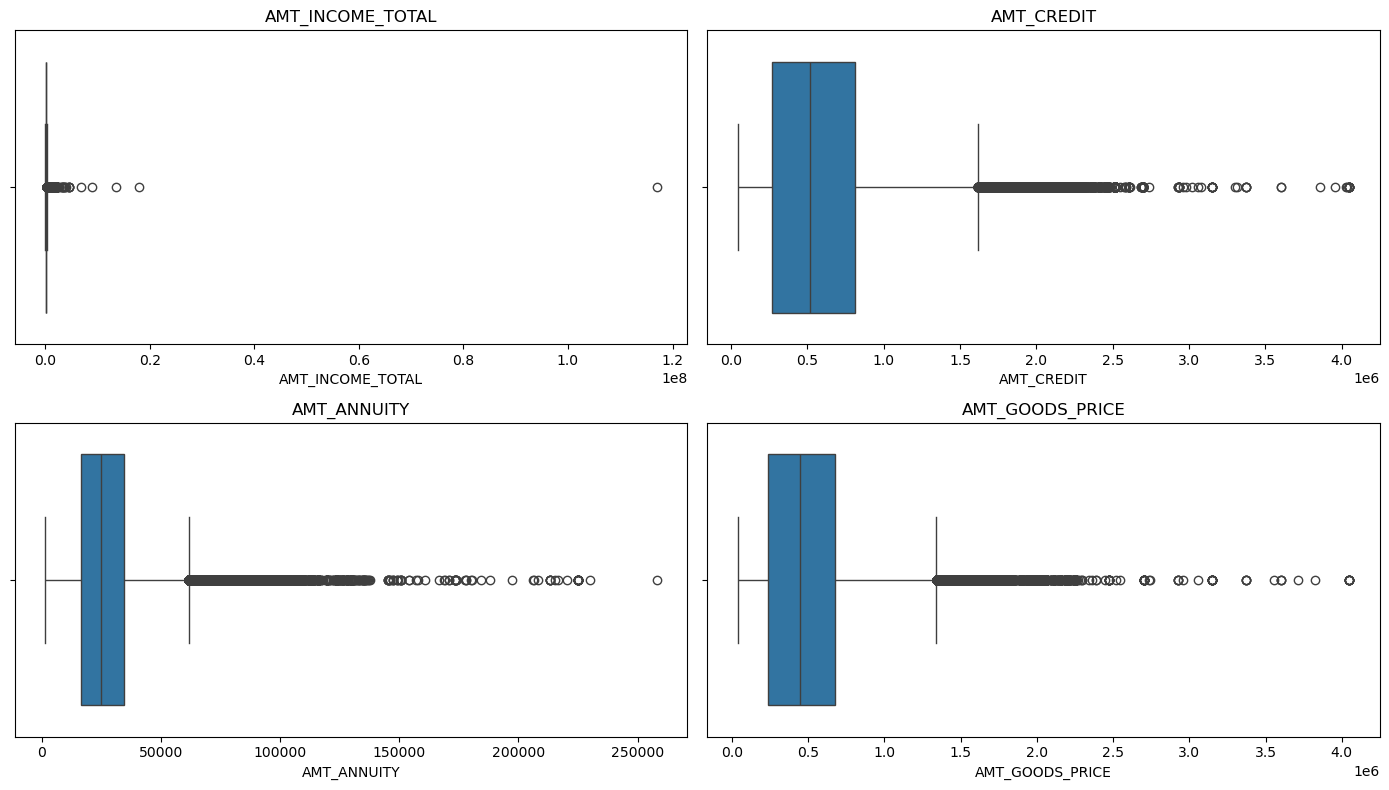

In [10]:

# Columns selected for outlier analysis

columns = ['AMT_INCOME_TOTAL', 'AMT_CREDIT',
           'AMT_ANNUITY', 'AMT_GOODS_PRICE']

# Create boxplots

plt.figure(figsize=(14, 8))

for i, col in enumerate(columns):
    plt.subplot(2, 2, i+1)
    sns.boxplot(x=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()


In [11]:

# Display the 10 customers with highest income

df[['SK_ID_CURR', 'AMT_INCOME_TOTAL',
    'AMT_CREDIT', 'AMT_ANNUITY']].sort_values(
    by='AMT_INCOME_TOTAL',
    ascending=False
).head(10)


,SK_ID_CURR,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY
12840,114967,117000000.0,562491.0,26194.5
203693,336147,18000090.0,675000.0,69295.5
246858,385674,13500000.0,1400503.5,130945.5
77768,190160,9000000.0,1431531.0,132601.5
131127,252084,6750000.0,790830.0,52978.5
103006,219563,4500000.0,2250000.0,225000.0
204564,337151,4500000.0,450000.0,47749.5
187833,317748,4500000.0,835380.0,42651.0
287463,432980,4500000.0,1755000.0,61132.5
181698,310601,3950059.5,675000.0,66217.5


In [12]:
# Check the record with the highest income

df.loc[df['AMT_INCOME_TOTAL'].idxmax(),
       ['SK_ID_CURR', 'AMT_INCOME_TOTAL',
        'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']]

SK_ID_CURR               114967
AMT_INCOME_TOTAL    117000000.0
AMT_CREDIT             562491.0
AMT_ANNUITY             26194.5
AMT_GOODS_PRICE        454500.0
Name: 12840, dtype: object

In [13]:
# Check the record with the highest loan amount

df.loc[df['AMT_CREDIT'].idxmax(),
       ['SK_ID_CURR', 'AMT_INCOME_TOTAL',
        'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']]

SK_ID_CURR             117337
AMT_INCOME_TOTAL     760846.5
AMT_CREDIT          4050000.0
AMT_ANNUITY          146002.5
AMT_GOODS_PRICE     4050000.0
Name: 14852, dtype: object

In [14]:

# Check unique categories in categorical columns

for col in categorical_columns:
    print(col, ":", df[col].nunique())


NAME_CONTRACT_TYPE : 2
CODE_GENDER : 3
FLAG_OWN_CAR : 2
FLAG_OWN_REALTY : 2
NAME_TYPE_SUITE : 7
NAME_INCOME_TYPE : 8
NAME_EDUCATION_TYPE : 5
NAME_FAMILY_STATUS : 6
NAME_HOUSING_TYPE : 6
OCCUPATION_TYPE : 18
WEEKDAY_APPR_PROCESS_START : 7
ORGANIZATION_TYPE : 58
FONDKAPREMONT_MODE : 4
HOUSETYPE_MODE : 3
WALLSMATERIAL_MODE : 7
EMERGENCYSTATE_MODE : 2


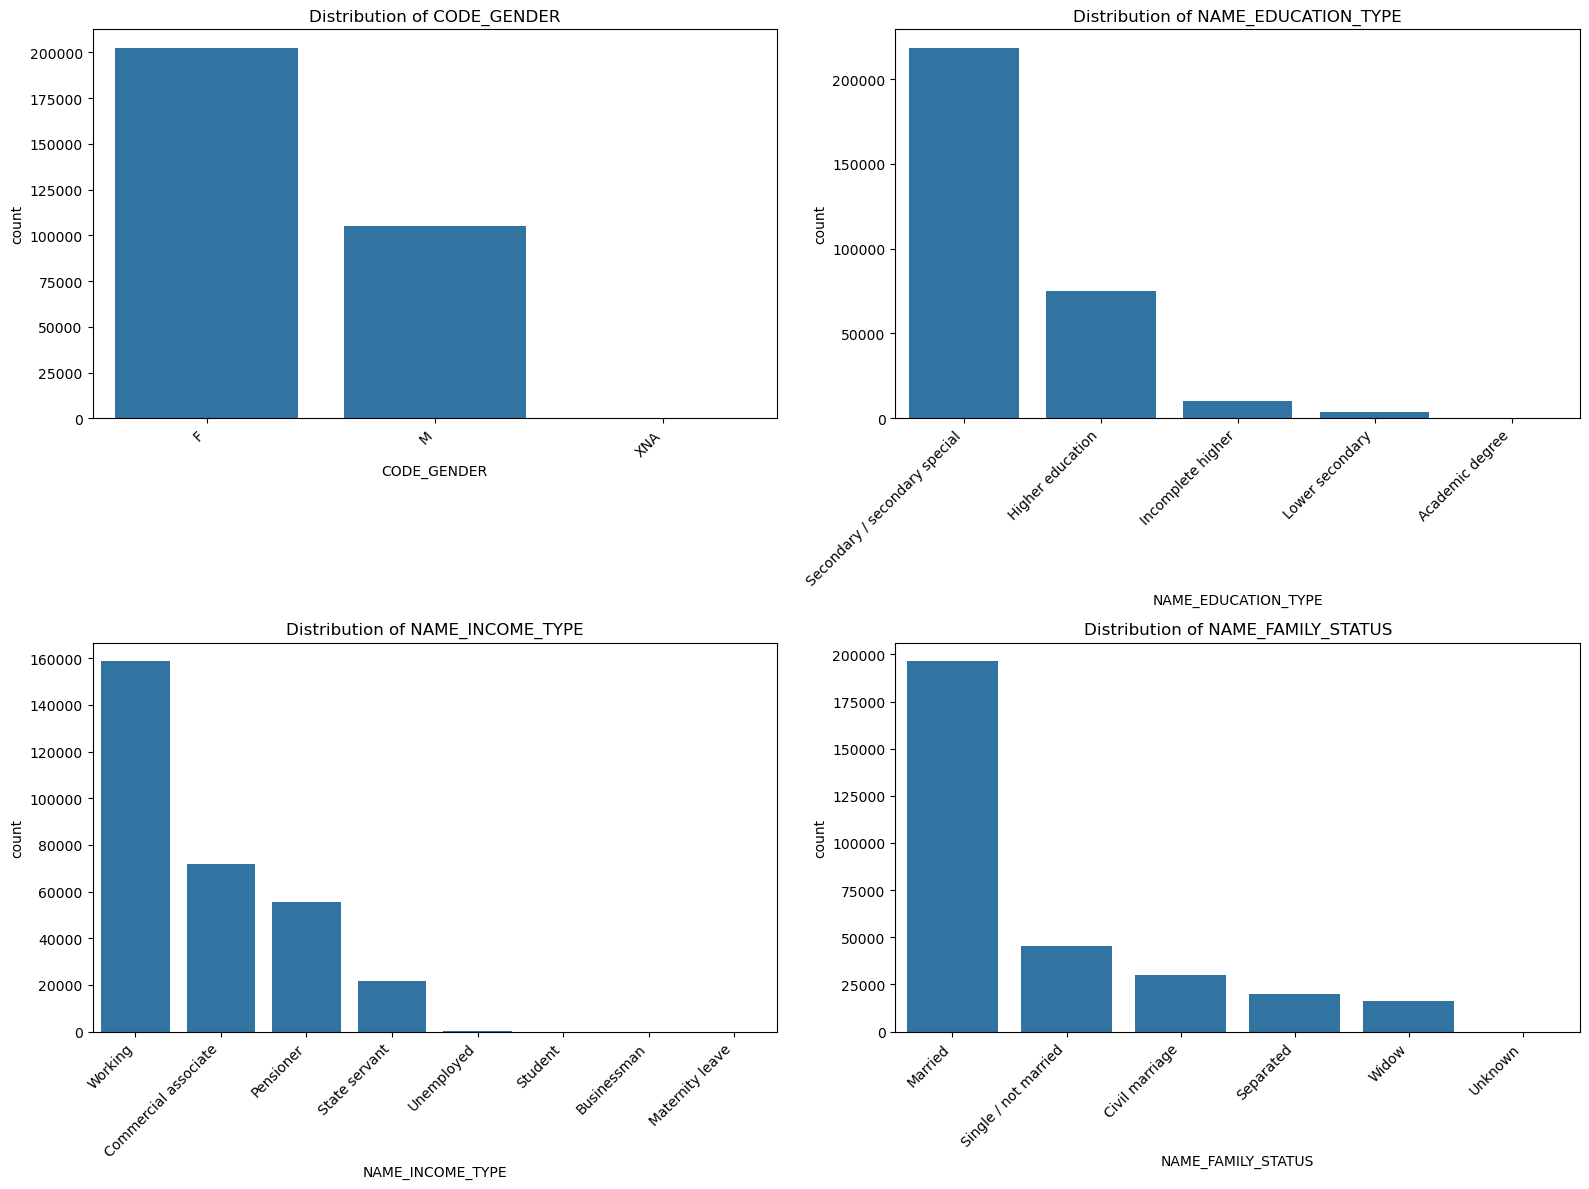

In [15]:

# Select categorical columns

columns = ['CODE_GENDER', 'NAME_EDUCATION_TYPE',
           'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS']

# Plot distributions

plt.figure(figsize=(16, 12))

for i, col in enumerate(columns):
    plt.subplot(2, 2, i+1)

    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index
    )

    plt.title(f'Distribution of {col}')
    plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()


In [16]:
columns = ['CODE_GENDER', 'NAME_EDUCATION_TYPE',
           'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS']

for col in columns:
    default_rate = df.groupby(col)['TARGET'].mean() * 100

    print(f"\nDefault Rate by {col} (%)")
    print(default_rate.sort_values(ascending=False).round(2))


Default Rate by CODE_GENDER (%)
CODE_GENDER
M      10.14
F       7.00
XNA     0.00
Name: TARGET, dtype: float64

Default Rate by NAME_EDUCATION_TYPE (%)
NAME_EDUCATION_TYPE
Lower secondary                  10.93
Secondary / secondary special     8.94
Incomplete higher                 8.48
Higher education                  5.36
Academic degree                   1.83
Name: TARGET, dtype: float64

Default Rate by NAME_INCOME_TYPE (%)
NAME_INCOME_TYPE
Maternity leave         40.00
Unemployed              36.36
Working                  9.59
Commercial associate     7.48
State servant            5.75
Pensioner                5.39
Businessman              0.00
Student                  0.00
Name: TARGET, dtype: float64

Default Rate by NAME_FAMILY_STATUS (%)
NAME_FAMILY_STATUS
Civil marriage          9.94
Single / not married    9.81
Separated               8.19
Married                 7.56
Widow                   5.82
Unknown                 0.00
Name: TARGET, dtype: float64


In [17]:
for col in columns:
    print(f"\nApplicant Counts by {col}")
    print(df[col].value_counts())


Applicant Counts by CODE_GENDER
CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

Applicant Counts by NAME_EDUCATION_TYPE
NAME_EDUCATION_TYPE
Secondary / secondary special    218391
Higher education                  74863
Incomplete higher                 10277
Lower secondary                    3816
Academic degree                     164
Name: count, dtype: int64

Applicant Counts by NAME_INCOME_TYPE
NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Unemployed                  22
Student                     18
Businessman                 10
Maternity leave              5
Name: count, dtype: int64

Applicant Counts by NAME_FAMILY_STATUS
NAME_FAMILY_STATUS
Married                 196432
Single / not married     45444
Civil marriage           29775
Separated                19770
Widow                    16088
Unknown                      2
Name: count, dtype: int64


In [18]:
columns2 = ['OCCUPATION_TYPE', 'ORGANIZATION_TYPE',
            'NAME_HOUSING_TYPE', 'NAME_CONTRACT_TYPE']

for col in columns2:
    print(f"\nDefault Rate by {col} (%)")
    print((df.groupby(col)['TARGET'].mean() * 100)
          .sort_values(ascending=False).round(2))


Default Rate by OCCUPATION_TYPE (%)
OCCUPATION_TYPE
Low-skill Laborers       17.15
Drivers                  11.33
Waiters/barmen staff     11.28
Security staff           10.74
Laborers                 10.58
Cooking staff            10.44
Sales staff               9.63
Cleaning staff            9.61
Realty agents             7.86
Secretaries               7.05
Medicine staff            6.70
Private service staff     6.60
IT staff                  6.46
HR staff                  6.39
Core staff                6.30
Managers                  6.21
High skill tech staff     6.16
Accountants               4.83
Name: TARGET, dtype: float64

Default Rate by ORGANIZATION_TYPE (%)
ORGANIZATION_TYPE
Transport: type 3         15.75
Industry: type 13         13.43
Industry: type 8          12.50
Restaurant                11.71
Construction              11.68
Cleaning                  11.15
Industry: type 1          11.07
Industry: type 3          10.62
Realtor                   10.61
Agriculture    

In [19]:
for col in columns2:
    print(f"\nApplicant Counts by {col}")
    print(df[col].value_counts())


Applicant Counts by OCCUPATION_TYPE
OCCUPATION_TYPE
Laborers                 55186
Sales staff              32102
Core staff               27570
Managers                 21371
Drivers                  18603
High skill tech staff    11380
Accountants               9813
Medicine staff            8537
Security staff            6721
Cooking staff             5946
Cleaning staff            4653
Private service staff     2652
Low-skill Laborers        2093
Waiters/barmen staff      1348
Secretaries               1305
Realty agents              751
HR staff                   563
IT staff                   526
Name: count, dtype: int64

Applicant Counts by ORGANIZATION_TYPE
ORGANIZATION_TYPE
Business Entity Type 3    67992
XNA                       55374
Self-employed             38412
Other                     16683
Medicine                  11193
Business Entity Type 2    10553
Government                10404
School                     8893
Trade: type 7              7831
Kindergarten      

In [20]:
categorical_columns = df.select_dtypes(include='object').columns

print(df[categorical_columns].isnull().sum().sort_values(ascending=False))

FONDKAPREMONT_MODE            210295
WALLSMATERIAL_MODE            156341
HOUSETYPE_MODE                154297
EMERGENCYSTATE_MODE           145755
OCCUPATION_TYPE                96391
NAME_TYPE_SUITE                 1292
NAME_CONTRACT_TYPE                 0
CODE_GENDER                        0
FLAG_OWN_CAR                       0
FLAG_OWN_REALTY                    0
NAME_INCOME_TYPE                   0
NAME_EDUCATION_TYPE                0
NAME_FAMILY_STATUS                 0
NAME_HOUSING_TYPE                  0
WEEKDAY_APPR_PROCESS_START         0
ORGANIZATION_TYPE                  0
dtype: int64


In [21]:
for col in categorical_columns:
    special_values = df[col].astype(str).str.upper().isin(['XNA', 'UNKNOWN']).sum()

    if special_values > 0:
        print(col, ":", special_values)

CODE_GENDER : 4
NAME_FAMILY_STATUS : 2
ORGANIZATION_TYPE : 55374


In [22]:
# numerical columns with missing values 

numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

numerical_missing = df[numerical_columns].isnull().sum()
numerical_missing = numerical_missing[numerical_missing > 0]

print(numerical_missing.sort_values(ascending=False))

COMMONAREA_MODE             214865
COMMONAREA_MEDI             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_AVG     213514
                             ...  
EXT_SOURCE_2                   660
AMT_GOODS_PRICE                278
AMT_ANNUITY                     12
CNT_FAM_MEMBERS                  2
DAYS_LAST_PHONE_CHANGE           1
Length: 61, dtype: int64


In [23]:
# identifying the percentage of missing values

numerical_missing_pct = (
    df[numerical_columns].isnull().mean() * 100
)

numerical_missing_pct = numerical_missing_pct[
    numerical_missing_pct > 0
].sort_values(ascending=False)

print(numerical_missing_pct.head(20).round(2))

COMMONAREA_MODE             69.87
COMMONAREA_MEDI             69.87
COMMONAREA_AVG              69.87
NONLIVINGAPARTMENTS_MODE    69.43
NONLIVINGAPARTMENTS_AVG     69.43
NONLIVINGAPARTMENTS_MEDI    69.43
LIVINGAPARTMENTS_MEDI       68.35
LIVINGAPARTMENTS_AVG        68.35
LIVINGAPARTMENTS_MODE       68.35
FLOORSMIN_MEDI              67.85
FLOORSMIN_MODE              67.85
FLOORSMIN_AVG               67.85
YEARS_BUILD_AVG             66.50
YEARS_BUILD_MODE            66.50
YEARS_BUILD_MEDI            66.50
OWN_CAR_AGE                 65.99
LANDAREA_MEDI               59.38
LANDAREA_MODE               59.38
LANDAREA_AVG                59.38
BASEMENTAREA_MODE           58.52
dtype: float64


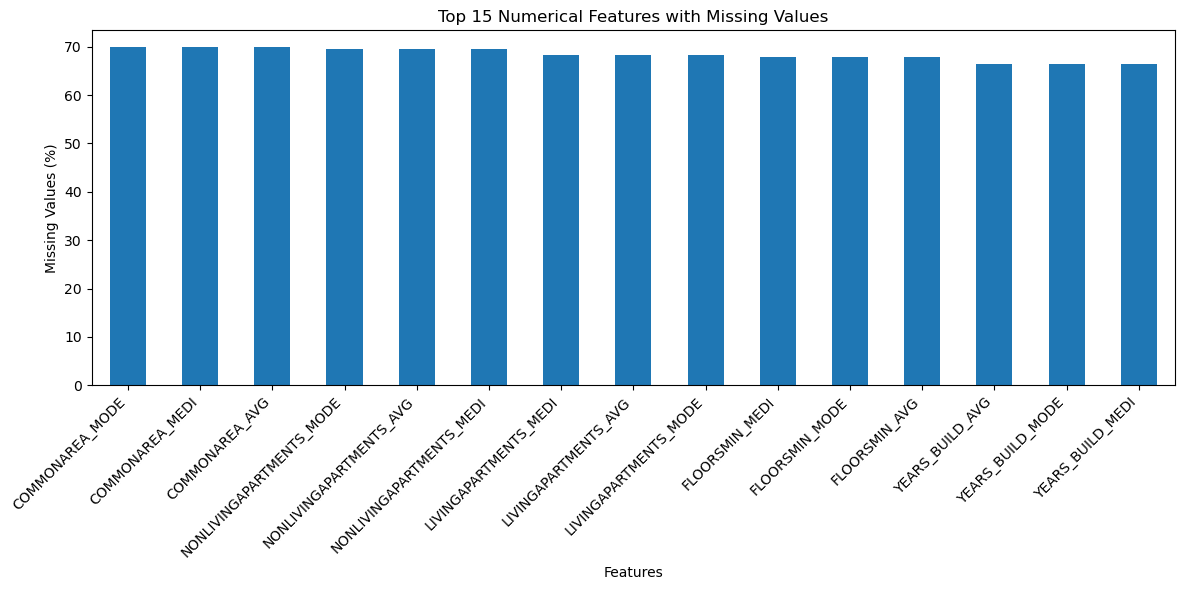

In [24]:
# visualizing numerical missing values

plt.figure(figsize=(12, 6))

numerical_missing_pct.head(15).plot(kind='bar')

plt.title('Top 15 Numerical Features with Missing Values')
plt.ylabel('Missing Values (%)')
plt.xlabel('Features')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [25]:
# Check missing percentages across all numerical columns

print(numerical_missing_pct.round(2).to_string())

COMMONAREA_MODE                 69.87
COMMONAREA_MEDI                 69.87
COMMONAREA_AVG                  69.87
NONLIVINGAPARTMENTS_MODE        69.43
NONLIVINGAPARTMENTS_AVG         69.43
NONLIVINGAPARTMENTS_MEDI        69.43
LIVINGAPARTMENTS_MEDI           68.35
LIVINGAPARTMENTS_AVG            68.35
LIVINGAPARTMENTS_MODE           68.35
FLOORSMIN_MEDI                  67.85
FLOORSMIN_MODE                  67.85
FLOORSMIN_AVG                   67.85
YEARS_BUILD_AVG                 66.50
YEARS_BUILD_MODE                66.50
YEARS_BUILD_MEDI                66.50
OWN_CAR_AGE                     65.99
LANDAREA_MEDI                   59.38
LANDAREA_MODE                   59.38
LANDAREA_AVG                    59.38
BASEMENTAREA_MODE               58.52
BASEMENTAREA_AVG                58.52
BASEMENTAREA_MEDI               58.52
EXT_SOURCE_1                    56.38
NONLIVINGAREA_MODE              55.18
NONLIVINGAREA_AVG               55.18
NONLIVINGAREA_MEDI              55.18
ELEVATORS_ME

In [26]:
# examine correlations between numerical features

target_corr = df[numerical_columns].corr()['TARGET'].sort_values(
    ascending=False
)

print(target_corr)

TARGET                         1.000000
DAYS_BIRTH                     0.078239
REGION_RATING_CLIENT_W_CITY    0.060893
REGION_RATING_CLIENT           0.058899
DAYS_LAST_PHONE_CHANGE         0.055218
                                 ...   
FLOORSMAX_AVG                 -0.044003
DAYS_EMPLOYED                 -0.044932
EXT_SOURCE_1                  -0.155317
EXT_SOURCE_2                  -0.160472
EXT_SOURCE_3                  -0.178919
Name: TARGET, Length: 106, dtype: float64


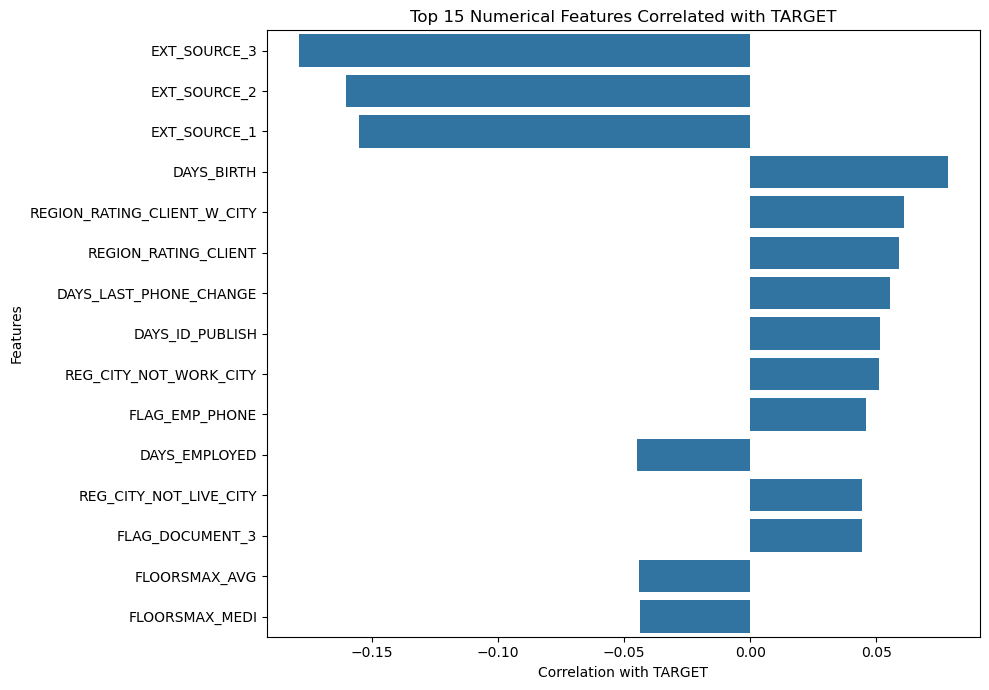

In [27]:
# Visualize the strongest correlations

top_corr = target_corr.drop('TARGET').abs().sort_values(
    ascending=False
).head(15).index

plt.figure(figsize=(10, 7))

sns.barplot(
    x=target_corr[top_corr].values,
    y=top_corr
)

plt.title('Top 15 Numerical Features Correlated with TARGET')
plt.xlabel('Correlation with TARGET')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

In [28]:
print("Applicants with DAYS_EMPLOYED = 365243:",
      (df['DAYS_EMPLOYED'] == 365243).sum())

print("Percentage:",
      round((df['DAYS_EMPLOYED'] == 365243).mean() * 100, 2), "%")

Applicants with DAYS_EMPLOYED = 365243: 55374
Percentage: 18.01 %


In [29]:
df['EMPLOYMENT_INFO_MISSING'] = (
    df['DAYS_EMPLOYED'] == 365243
).astype(int)

print(
    df.groupby('EMPLOYMENT_INFO_MISSING')['TARGET']
    .agg(['count', 'mean'])
)

                          count      mean
EMPLOYMENT_INFO_MISSING                  
0                        252137  0.086600
1                         55374  0.053996


In [30]:
for col in ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']:

    df[col + '_GROUP'] = pd.qcut(
        df[col],
        q=5,
        duplicates='drop'
    )

    print("\n", col)
    print(
        df.groupby(col + '_GROUP', observed=True)['TARGET']
        .mean()
    )


 EXT_SOURCE_1
EXT_SOURCE_1_GROUP
(0.013600000000000001, 0.296]    0.145786
(0.296, 0.438]                   0.087378
(0.438, 0.573]                   0.063593
(0.573, 0.71]                    0.047603
(0.71, 0.963]                    0.030417
Name: TARGET, dtype: float64

 EXT_SOURCE_2
EXT_SOURCE_2_GROUP
(-0.0009999183, 0.34]    0.152140
(0.34, 0.512]            0.091607
(0.512, 0.608]           0.070392
(0.608, 0.682]           0.053652
(0.682, 0.855]           0.035870
Name: TARGET, dtype: float64

 EXT_SOURCE_3
EXT_SOURCE_3_GROUP
(-0.000473, 0.33]    0.163758
(0.33, 0.476]        0.087505
(0.476, 0.592]       0.057505
(0.592, 0.694]       0.044795
(0.694, 0.896]       0.033763
Name: TARGET, dtype: float64


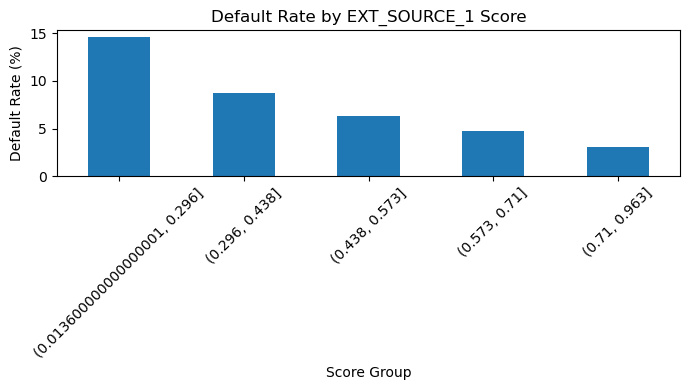

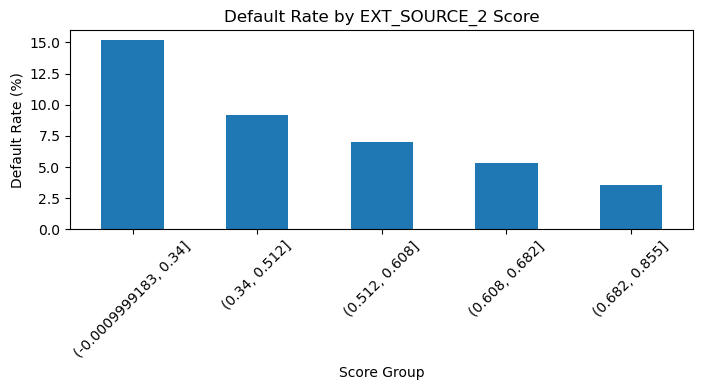

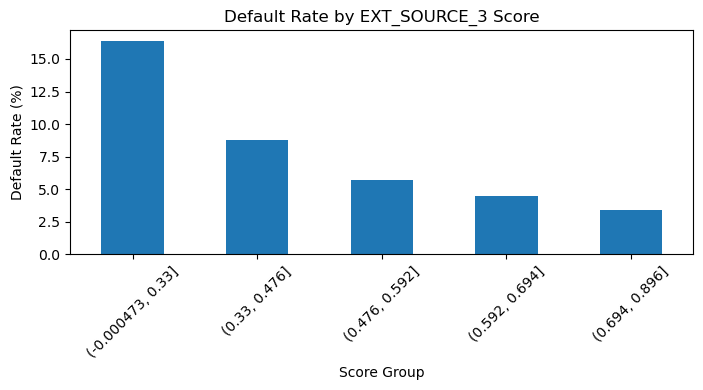

In [31]:
for col in ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']:

    rate = df.groupby(
        col + '_GROUP', observed=True
    )['TARGET'].mean() * 100

    rate.plot(kind='bar', figsize=(7, 4))

    plt.title(f'Default Rate by {col} Score')
    plt.xlabel('Score Group')
    plt.ylabel('Default Rate (%)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [32]:
df['AGE'] = abs(df['DAYS_BIRTH']) / 365

df['AGE_GROUP'] = pd.cut(
    df['AGE'],
    bins=[20, 25, 30, 35, 40, 45, 50, 55, 60, 70],
)

print(
    df.groupby('AGE_GROUP', observed=True)['TARGET']
    .mean() * 100
)

AGE_GROUP
(20, 25]    12.303643
(25, 30]    11.143570
(30, 35]    10.281440
(35, 40]     8.941402
(40, 45]     7.849104
(45, 50]     7.417105
(50, 55]     6.696812
(55, 60]     5.531401
(60, 70]     4.921442
Name: TARGET, dtype: float64


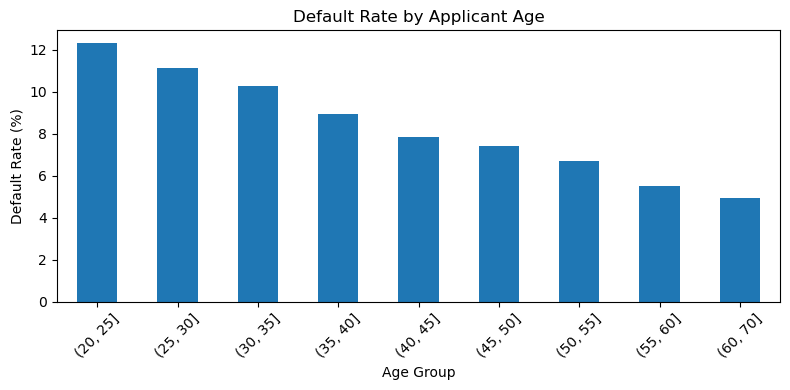

In [33]:
age_default_rate = (
    df.groupby('AGE_GROUP', observed=True)['TARGET'].mean() * 100
)

age_default_rate.plot(
    kind='bar',
    figsize=(8, 4)
)

plt.title('Default Rate by Applicant Age')
plt.xlabel('Age Group')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [34]:
df['EMPLOYMENT_YEARS'] = (
    df['DAYS_EMPLOYED'].replace(365243, np.nan).abs() / 365
)

print(df['EMPLOYMENT_YEARS'].describe())

count    252137.000000
mean          6.531971
std           6.406466
min           0.000000
25%           2.101370
50%           4.515068
75%           8.698630
max          49.073973
Name: EMPLOYMENT_YEARS, dtype: float64


In [35]:
df['EMPLOYMENT_GROUP'] = pd.cut(
    df['EMPLOYMENT_YEARS'],
    bins=[0, 1, 3, 5, 10, 20, 50]
)

print(
    df.groupby('EMPLOYMENT_GROUP', observed=True)['TARGET']
    .agg(['count', 'mean'])
)

                  count      mean
EMPLOYMENT_GROUP                 
(0, 1]            27980  0.109685
(1, 3]            61472  0.110733
(3, 5]            46857  0.096741
(5, 10]           64872  0.073714
(10, 20]          38398  0.055133
(20, 50]          12556  0.041892


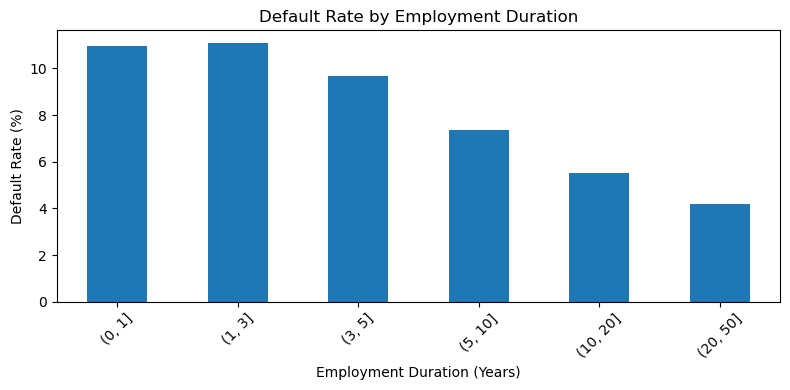

In [36]:
employment_default_rate = (
    df.groupby('EMPLOYMENT_GROUP', observed=True)['TARGET'].mean() * 100
)

employment_default_rate.plot(
    kind='bar',
    figsize=(8, 4)
)

plt.title('Default Rate by Employment Duration')
plt.xlabel('Employment Duration (Years)')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [37]:
df['INCOME_GROUP'] = pd.qcut(
    df['AMT_INCOME_TOTAL'],
    q=5,
    duplicates='drop'
)

print(
    df.groupby('INCOME_GROUP', observed=True)['TARGET']
    .agg(['count', 'mean'])
)

                         count      mean
INCOME_GROUP                            
(25649.999, 99000.0]     63671  0.082062
(99000.0, 135000.0]      85756  0.085883
(135000.0, 162000.0]     35453  0.086847
(162000.0, 225000.0]     75513  0.080569
(225000.0, 117000000.0]  47118  0.065198


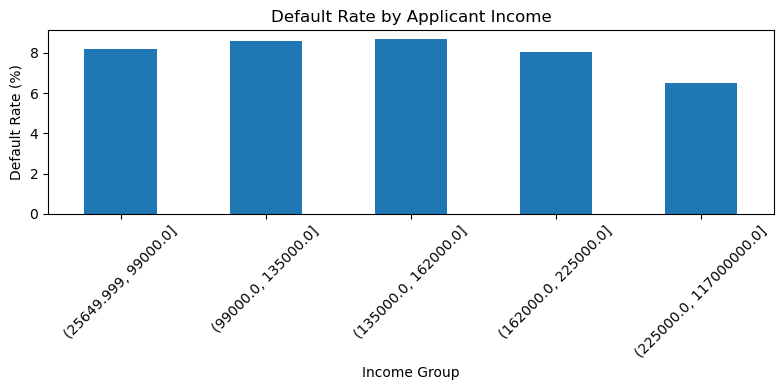

In [38]:
income_default_rate = (
    df.groupby('INCOME_GROUP', observed=True)['TARGET'].mean() * 100
)

income_default_rate.plot(
    kind='bar',
    figsize=(8, 4)
)

plt.title('Default Rate by Applicant Income')
plt.xlabel('Income Group')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [39]:
df['CREDIT_GROUP'] = pd.qcut(
    df['AMT_CREDIT'],
    q=5,
    duplicates='drop'
)

print(
    df.groupby('CREDIT_GROUP', observed=True)['TARGET']
    .agg(['count', 'mean'])
)

                       count      mean
CREDIT_GROUP                          
(44999.999, 254700.0]  64925  0.072376
(254700.0, 432000.0]   58098  0.091724
(432000.0, 604152.0]   61552  0.100549
(604152.0, 900000.0]   64024  0.078549
(900000.0, 4050000.0]  58912  0.060752


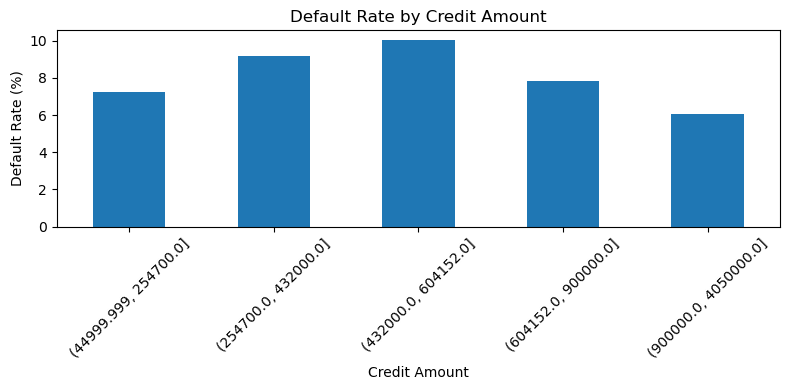

In [40]:
credit_default_rate = (
    df.groupby('CREDIT_GROUP', observed=True)['TARGET'].mean() * 100
)

credit_default_rate.plot(
    kind='bar',
    figsize=(8, 4)
)

plt.title('Default Rate by Credit Amount')
plt.xlabel('Credit Amount')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [41]:
df['CREDIT_INCOME_RATIO'] = (
    df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL']
)

print(df['CREDIT_INCOME_RATIO'].describe())

count    307511.000000
mean          3.957570
std           2.689728
min           0.004808
25%           2.018667
50%           3.265067
75%           5.159880
max          84.736842
Name: CREDIT_INCOME_RATIO, dtype: float64


In [42]:
df['CREDIT_INCOME_GROUP'] = pd.qcut(
    df['CREDIT_INCOME_RATIO'],
    q=5,
    duplicates='drop'
)

print(
    df.groupby('CREDIT_INCOME_GROUP', observed=True)['TARGET']
    .agg(['count', 'mean'])
)

                     count      mean
CREDIT_INCOME_GROUP                 
(0.00381, 1.818]     61539  0.073352
(1.818, 2.764]       61502  0.085672
(2.764, 3.906]       61466  0.089253
(3.906, 5.769]       61505  0.082839
(5.769, 84.737]      61499  0.072538


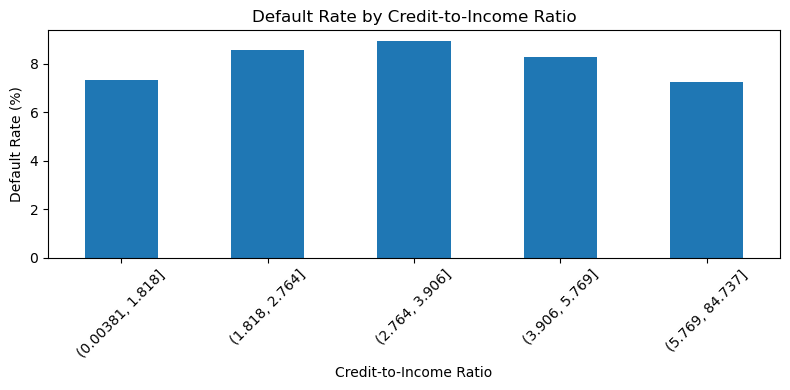

In [43]:
ratio_default_rate = (
    df.groupby('CREDIT_INCOME_GROUP', observed=True)['TARGET'].mean() * 100
)

ratio_default_rate.plot(
    kind='bar',
    figsize=(8, 4)
)

plt.title('Default Rate by Credit-to-Income Ratio')
plt.xlabel('Credit-to-Income Ratio')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [44]:
df['ANNUITY_GROUP'] = pd.qcut(
    df['AMT_ANNUITY'],
    q=5,
    duplicates='drop'
)

print(
    df.groupby('ANNUITY_GROUP', observed=True)['TARGET']
    .agg(['count', 'mean'])
)

                     count      mean
ANNUITY_GROUP                       
(1615.499, 14701.5]  61507  0.069488
(14701.5, 21865.5]   61494  0.085830
(21865.5, 28062.0]   61562  0.087911
(28062.0, 37516.5]   61452  0.093390
(37516.5, 258025.5]  61484  0.067042


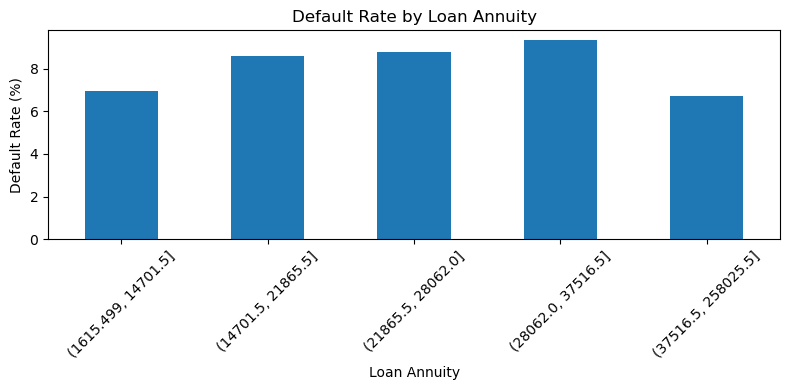

In [45]:
annuity_default_rate = (
    df.groupby('ANNUITY_GROUP', observed=True)['TARGET'].mean() * 100
)

annuity_default_rate.plot(
    kind='bar',
    figsize=(8, 4)
)

plt.title('Default Rate by Loan Annuity')
plt.xlabel('Loan Annuity')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [46]:
df['GOODS_PRICE_GROUP'] = pd.qcut(
    df['AMT_GOODS_PRICE'],
    q=5,
    duplicates='drop'
)

print(
    df.groupby('GOODS_PRICE_GROUP', observed=True)['TARGET']
    .agg(['count', 'mean'])
)

                       count      mean
GOODS_PRICE_GROUP                     
(40499.999, 225000.0]  71454  0.080121
(225000.0, 373500.0]   51473  0.087930
(373500.0, 522000.0]   61527  0.103759
(522000.0, 814500.0]   61349  0.075796
(814500.0, 4050000.0]  61430  0.057285


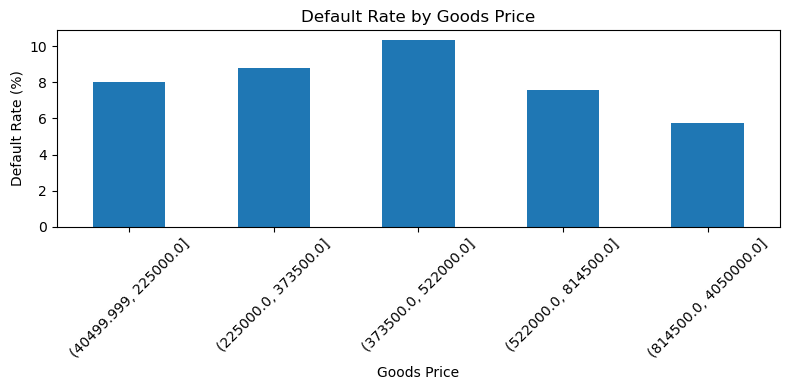

In [47]:
goods_default_rate = (
    df.groupby('GOODS_PRICE_GROUP', observed=True)['TARGET'].mean() * 100
)

goods_default_rate.plot(
    kind='bar',
    figsize=(8, 4)
)

plt.title('Default Rate by Goods Price')
plt.xlabel('Goods Price')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [48]:
print(
    df.groupby('CNT_FAM_MEMBERS')['TARGET']
    .agg(['count', 'mean'])
)

                  count      mean
CNT_FAM_MEMBERS                  
1.0               67847  0.083644
2.0              158357  0.075835
3.0               52601  0.087603
4.0               24697  0.086488
5.0                3478  0.094020
6.0                 408  0.134804
7.0                  81  0.074074
8.0                  20  0.300000
9.0                   6  0.000000
10.0                  3  0.333333
11.0                  1  1.000000
12.0                  2  0.000000
13.0                  1  1.000000
14.0                  2  0.000000
15.0                  1  0.000000
16.0                  2  0.000000
20.0                  2  0.000000


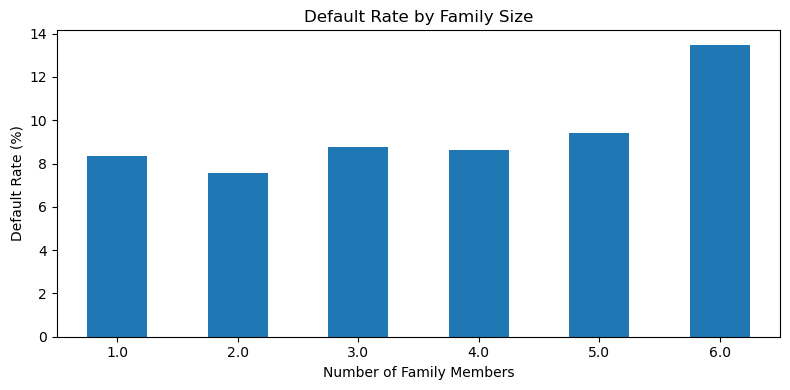

In [49]:
family_data = df.groupby('CNT_FAM_MEMBERS')['TARGET'].agg(
    ['count', 'mean']
)

family_data = family_data[family_data['count'] >= 100]

(family_data['mean'] * 100).plot(
    kind='bar',
    figsize=(8, 4)
)

plt.title('Default Rate by Family Size')
plt.xlabel('Number of Family Members')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [50]:
print(
    df.groupby('CNT_CHILDREN')['TARGET']
    .agg(['count', 'mean'])
)

               count      mean
CNT_CHILDREN                  
0             215371  0.077118
1              61119  0.089236
2              26749  0.087218
3               3717  0.096314
4                429  0.128205
5                 84  0.083333
6                 21  0.285714
7                  7  0.000000
8                  2  0.000000
9                  2  1.000000
10                 2  0.000000
11                 1  1.000000
12                 2  0.000000
14                 3  0.000000
19                 2  0.000000


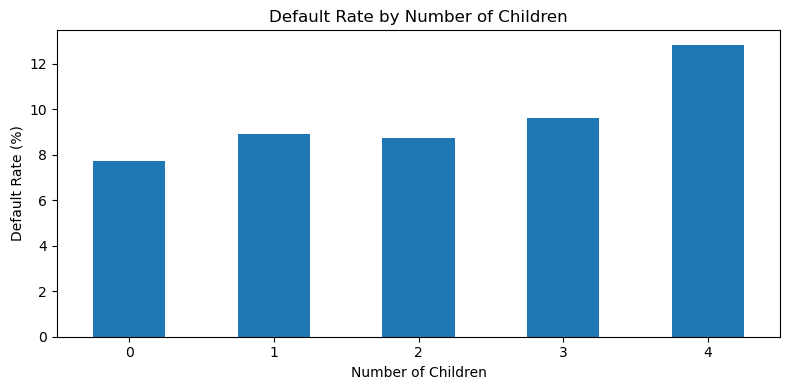

In [51]:
children_data = df.groupby('CNT_CHILDREN')['TARGET'].agg(
    ['count', 'mean']
)

children_data = children_data[children_data['count'] >= 100]

(children_data['mean'] * 100).plot(
    kind='bar',
    figsize=(8, 4)
)

plt.title('Default Rate by Number of Children')
plt.xlabel('Number of Children')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [52]:
print(
    df.groupby('FLAG_OWN_CAR')['TARGET']
    .agg(['count', 'mean'])
)

               count      mean
FLAG_OWN_CAR                  
N             202924  0.085002
Y             104587  0.072437


In [53]:
print(
    df.groupby('FLAG_OWN_REALTY')['TARGET']
    .agg(['count', 'mean'])
)

                  count      mean
FLAG_OWN_REALTY                  
N                 94199  0.083249
Y                213312  0.079616


In [54]:
print(
    df.groupby('REGION_RATING_CLIENT')['TARGET']
    .agg(['count', 'mean'])
)

                       count      mean
REGION_RATING_CLIENT                  
1                      32197  0.048203
2                     226984  0.078891
3                      48330  0.111028


In [55]:
df['ID_DOCUMENT_AGE_YEARS'] = (
    abs(df['DAYS_ID_PUBLISH']) / 365
)

df['ID_DOCUMENT_GROUP'] = pd.cut(
    df['ID_DOCUMENT_AGE_YEARS'],
    bins=[0, 2, 5, 10, 15, 20, 30]
)

print(
    df.groupby('ID_DOCUMENT_GROUP', observed=True)['TARGET']
    .agg(['count', 'mean'])
)

                    count      mean
ID_DOCUMENT_GROUP                  
(0, 2]              30769  0.101791
(2, 5]              51032  0.096841
(5, 10]             92698  0.084554
(10, 15]           130120  0.067253
(15, 20]             2876  0.055633


In [56]:
print(
    "Applicants outside the document-age groups:",
    df['ID_DOCUMENT_GROUP'].isna().sum()
)

Applicants outside the document-age groups: 16


In [57]:
model_df = df.copy()

print("Original dataset shape:", df.shape)
print("Modelling dataset shape:", model_df.shape)

Original dataset shape: (307511, 138)
Modelling dataset shape: (307511, 138)


In [58]:
model_df['DAYS_EMPLOYED'] = (
    model_df['DAYS_EMPLOYED'].replace(365243, np.nan)
)

print("Missing DAYS_EMPLOYED values:",
      model_df['DAYS_EMPLOYED'].isnull().sum())

Missing DAYS_EMPLOYED values: 55374


In [59]:
print("CODE_GENDER:")
print(model_df['CODE_GENDER'].value_counts(dropna=False))

print("\nNAME_FAMILY_STATUS:")
print(model_df['NAME_FAMILY_STATUS'].value_counts(dropna=False))

print("\nORGANIZATION_TYPE:")
print(model_df['ORGANIZATION_TYPE'].value_counts(dropna=False).head(10))

CODE_GENDER:
CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

NAME_FAMILY_STATUS:
NAME_FAMILY_STATUS
Married                 196432
Single / not married     45444
Civil marriage           29775
Separated                19770
Widow                    16088
Unknown                      2
Name: count, dtype: int64

ORGANIZATION_TYPE:
ORGANIZATION_TYPE
Business Entity Type 3    67992
XNA                       55374
Self-employed             38412
Other                     16683
Medicine                  11193
Business Entity Type 2    10553
Government                10404
School                     8893
Trade: type 7              7831
Kindergarten               6880
Name: count, dtype: int64


In [60]:
model_df['CODE_GENDER'] = (
    model_df['CODE_GENDER'].replace('XNA', np.nan)
)

model_df['NAME_FAMILY_STATUS'] = (
    model_df['NAME_FAMILY_STATUS'].replace('Unknown', np.nan)
)

print("Gender missing:", model_df['CODE_GENDER'].isnull().sum())
print("Family status missing:", model_df['NAME_FAMILY_STATUS'].isnull().sum())
print("Organization XNA:",
      (model_df['ORGANIZATION_TYPE'] == 'XNA').sum())

Gender missing: 4
Family status missing: 2
Organization XNA: 55374


In [61]:
missing_data = pd.DataFrame({
    'Missing_Count': model_df.isnull().sum(),
    'Missing_Percentage': model_df.isnull().mean() * 100
})

missing_data = missing_data[
    missing_data['Missing_Count'] > 0
].sort_values(
    by='Missing_Percentage',
    ascending=False
)

print("Columns with missing values:", len(missing_data))
print(missing_data.head(20))

Columns with missing values: 78
                          Missing_Count  Missing_Percentage
COMMONAREA_MEDI                  214865           69.872297
COMMONAREA_MODE                  214865           69.872297
COMMONAREA_AVG                   214865           69.872297
NONLIVINGAPARTMENTS_MODE         213514           69.432963
NONLIVINGAPARTMENTS_MEDI         213514           69.432963
NONLIVINGAPARTMENTS_AVG          213514           69.432963
FONDKAPREMONT_MODE               210295           68.386172
LIVINGAPARTMENTS_MODE            210199           68.354953
LIVINGAPARTMENTS_AVG             210199           68.354953
LIVINGAPARTMENTS_MEDI            210199           68.354953
FLOORSMIN_MEDI                   208642           67.848630
FLOORSMIN_MODE                   208642           67.848630
FLOORSMIN_AVG                    208642           67.848630
YEARS_BUILD_MEDI                 204488           66.497784
YEARS_BUILD_AVG                  204488           66.497784
YEARS_BU

In [62]:
eda_group_columns = [
    'EXT_SOURCE_1_GROUP',
    'EXT_SOURCE_2_GROUP',
    'EXT_SOURCE_3_GROUP',
    'AGE_GROUP',
    'EMPLOYMENT_GROUP',
    'INCOME_GROUP',
    'CREDIT_GROUP',
    'CREDIT_INCOME_GROUP',
    'ANNUITY_GROUP',
    'GOODS_PRICE_GROUP',
    'ID_DOCUMENT_GROUP'
]

model_df.drop(columns=eda_group_columns, inplace=True)

print("Updated modelling dataset shape:", model_df.shape)
print("Columns remaining with missing values:",
      model_df.isnull().any().sum())

Updated modelling dataset shape: (307511, 127)
Columns remaining with missing values: 71


In [63]:
high_missing = (
    model_df.isnull().mean() * 100
)

high_missing = high_missing[high_missing > 60].sort_values(
    ascending=False
)

print("Columns with more than 60% missing values:")
print(high_missing)

print("\nTotal columns:", len(high_missing))

Columns with more than 60% missing values:
COMMONAREA_MEDI             69.872297
COMMONAREA_AVG              69.872297
COMMONAREA_MODE             69.872297
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
NONLIVINGAPARTMENTS_MODE    69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_MODE       68.354953
FLOORSMIN_MEDI              67.848630
FLOORSMIN_MODE              67.848630
FLOORSMIN_AVG               67.848630
YEARS_BUILD_MEDI            66.497784
YEARS_BUILD_AVG             66.497784
YEARS_BUILD_MODE            66.497784
OWN_CAR_AGE                 65.990810
dtype: float64

Total columns: 17


In [64]:
high_missing_cols = (
    model_df.columns[
        model_df.isnull().mean() > 0.60
    ]
)

model_df.drop(
    columns=high_missing_cols,
    inplace=True
)

print("Columns removed:", len(high_missing_cols))
print("Updated dataset shape:", model_df.shape)

Columns removed: 17
Updated dataset shape: (307511, 110)


In [65]:
remaining_missing = model_df.isnull().sum()

remaining_missing = remaining_missing[
    remaining_missing > 0
].sort_values(ascending=False)

print("Remaining columns with missing values:",
      len(remaining_missing))

print(remaining_missing)

Remaining columns with missing values: 54
LANDAREA_AVG                    182590
LANDAREA_MODE                   182590
LANDAREA_MEDI                   182590
BASEMENTAREA_MEDI               179943
BASEMENTAREA_AVG                179943
BASEMENTAREA_MODE               179943
EXT_SOURCE_1                    173378
NONLIVINGAREA_MODE              169682
NONLIVINGAREA_MEDI              169682
NONLIVINGAREA_AVG               169682
ELEVATORS_MEDI                  163891
ELEVATORS_AVG                   163891
ELEVATORS_MODE                  163891
WALLSMATERIAL_MODE              156341
APARTMENTS_MEDI                 156061
APARTMENTS_AVG                  156061
APARTMENTS_MODE                 156061
ENTRANCES_MODE                  154828
ENTRANCES_MEDI                  154828
ENTRANCES_AVG                   154828
LIVINGAREA_AVG                  154350
LIVINGAREA_MEDI                 154350
LIVINGAREA_MODE                 154350
HOUSETYPE_MODE                  154297
FLOORSMAX_MEDI        

In [66]:
numerical_missing = model_df.select_dtypes(
    include=np.number
).columns[
    model_df.select_dtypes(include=np.number).isnull().any()
]

categorical_missing = model_df.select_dtypes(
    include='object'
).columns[
    model_df.select_dtypes(include='object').isnull().any()
]

print("Numerical columns with missing values:")
print(list(numerical_missing))

print("\nTotal numerical columns:", len(numerical_missing))

print("\nCategorical columns with missing values:")
print(list(categorical_missing))

print("\nTotal categorical columns:", len(categorical_missing))

Numerical columns with missing values:
['AMT_ANNUITY', 'AMT_GOODS_PRICE', 'DAYS_EMPLOYED', 'CNT_FAM_MEMBERS', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMAX_AVG', 'LANDAREA_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAREA_AVG', 'APARTMENTS_MODE', 'BASEMENTAREA_MODE', 'YEARS_BEGINEXPLUATATION_MODE', 'ELEVATORS_MODE', 'ENTRANCES_MODE', 'FLOORSMAX_MODE', 'LANDAREA_MODE', 'LIVINGAREA_MODE', 'NONLIVINGAREA_MODE', 'APARTMENTS_MEDI', 'BASEMENTAREA_MEDI', 'YEARS_BEGINEXPLUATATION_MEDI', 'ELEVATORS_MEDI', 'ENTRANCES_MEDI', 'FLOORSMAX_MEDI', 'LANDAREA_MEDI', 'LIVINGAREA_MEDI', 'NONLIVINGAREA_MEDI', 'TOTALAREA_MODE', 'OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE', 'DAYS_LAST_PHONE_CHANGE', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QR

In [67]:
X = model_df.drop(
    columns=['TARGET', 'SK_ID_CURR']
)

y = model_df['TARGET']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (307511, 108)
Target shape: (307511,)


# Task 2: Predictive Model¶

In [68]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (246008, 108)
Testing features: (61503, 108)

Training target distribution:
TARGET
0    91.927092
1     8.072908
Name: proportion, dtype: float64

Testing target distribution:
TARGET
0    91.927223
1     8.072777
Name: proportion, dtype: float64


In [69]:
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include='object'
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nCategorical columns:")
print(categorical_features)

Numerical features: 93
Categorical features: 15

Categorical columns:
['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [70]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [71]:
# Numerical preprocessing
numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [72]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)

In [73]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (246008, 234)
Processed testing shape: (61503, 234)


In [74]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [75]:
y_pred = logistic_model.predict(X_test_processed)

y_pred_proba = logistic_model.predict_proba(X_test_processed)[:, 1]

print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 default probabilities:")
print(y_pred_proba[:10])

First 10 predictions:
[0 0 1 1 1 1 0 0 1 0]

First 10 default probabilities:
[0.37994618 0.33244987 0.77163073 0.56140854 0.60112308 0.64880556
 0.09503536 0.07243984 0.85000722 0.4168169 ]


In [76]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_pred_proba))

Accuracy: 0.689608636977058
Precision: 0.16092947333045274
Recall: 0.6751258811681773
F1 Score: 0.25990540435760257
ROC-AUC: 0.7486838019306464


In [77]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[39061 17477]
 [ 1613  3352]]


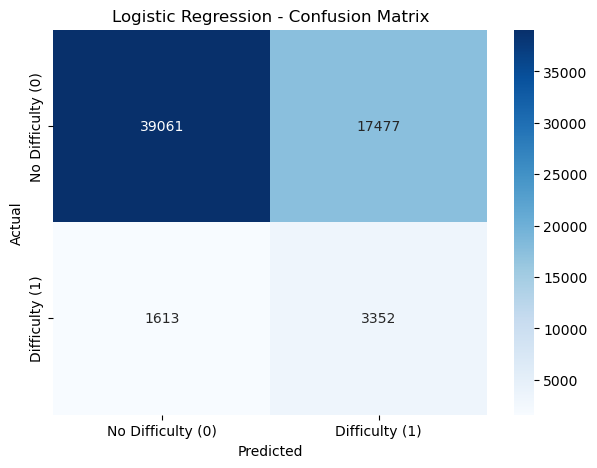

In [78]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Difficulty (0)', 'Difficulty (1)'],
    yticklabels=['No Difficulty (0)', 'Difficulty (1)']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [79]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(
    max_depth=10,
    min_samples_split=20,
    class_weight='balanced',
    random_state=42
)

dt_model.fit(X_train_processed, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,10
,min_samples_split,20
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


In [80]:
dt_pred = dt_model.predict(X_test_processed)

dt_pred_proba = dt_model.predict_proba(X_test_processed)[:, 1]

print("First 10 predictions:")
print(dt_pred[:10])

print("\nFirst 10 default probabilities:")
print(dt_pred_proba[:10])

First 10 predictions:
[1 0 1 0 1 1 0 0 1 0]

First 10 default probabilities:
[0.52980131 0.34514602 0.83980983 0.39043901 0.54871041 0.71013409
 0.18711608 0.09597799 0.89250583 0.40341213]


In [81]:
print("Accuracy:", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall:", recall_score(y_test, dt_pred))
print("F1 Score:", f1_score(y_test, dt_pred))
print("ROC-AUC:", roc_auc_score(y_test, dt_pred_proba))

Accuracy: 0.678763637546136
Precision: 0.14877956121189098
Recall: 0.6310171198388721
F1 Score: 0.24078699611881796
ROC-AUC: 0.7002052501152698


In [82]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=20,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,15
,min_samples_split,20
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [83]:
rf_pred = rf_model.predict(X_test_processed)

rf_pred_proba = rf_model.predict_proba(X_test_processed)[:, 1]

print("First 10 predictions:")
print(rf_pred[:10])

print("\nFirst 10 default probabilities:")
print(rf_pred_proba[:10])

First 10 predictions:
[0 0 0 0 0 1 0 0 1 0]

First 10 default probabilities:
[0.41042264 0.28455011 0.48066169 0.38733063 0.49348234 0.59797365
 0.15716029 0.1866477  0.70372369 0.36569069]


In [84]:
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_pred_proba))

Accuracy: 0.804497341593093
Precision: 0.19612569952647438
Recall: 0.45881168177240683
F1 Score: 0.274788902291918
ROC-AUC: 0.7303910172153107


In [85]:
!pip install xgboost

In [86]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [87]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("Scale positive weight:", scale_pos_weight)

Scale positive weight: 11.38710976837865


In [88]:
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_processed, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


In [89]:
xgb_pred = xgb_model.predict(X_test_processed)

xgb_pred_proba = xgb_model.predict_proba(X_test_processed)[:, 1]

print("First 10 predictions:")
print(xgb_pred[:10])

print("\nFirst 10 default probabilities:")
print(xgb_pred_proba[:10])

First 10 predictions:
[0 0 1 0 1 1 0 0 1 1]

First 10 default probabilities:
[0.34991017 0.32717776 0.81786776 0.4132246  0.508893   0.67310333
 0.1441102  0.08608547 0.8281217  0.52340597]


In [90]:
print("Accuracy:", accuracy_score(y_test, xgb_pred))
print("Precision:", precision_score(y_test, xgb_pred))
print("Recall:", recall_score(y_test, xgb_pred))
print("F1 Score:", f1_score(y_test, xgb_pred))
print("ROC-AUC:", roc_auc_score(y_test, xgb_pred_proba))

Accuracy: 0.7049574817488578
Precision: 0.1692014254881293
Recall: 0.6789526686807653
F1 Score: 0.2708936033429765
ROC-AUC: 0.7584129391787294


In [91]:
from sklearn.metrics import average_precision_score

print("Logistic Regression PR-AUC:",
      average_precision_score(y_test, y_pred_proba))

print("Decision Tree PR-AUC:",
      average_precision_score(y_test, dt_pred_proba))

print("Random Forest PR-AUC:",
      average_precision_score(y_test, rf_pred_proba))

print("XGBoost PR-AUC:",
      average_precision_score(y_test, xgb_pred_proba))

Logistic Regression PR-AUC: 0.2277709610124896
Decision Tree PR-AUC: 0.18569299838020903
Random Forest PR-AUC: 0.20788345490756488
XGBoost PR-AUC: 0.24811010372649323


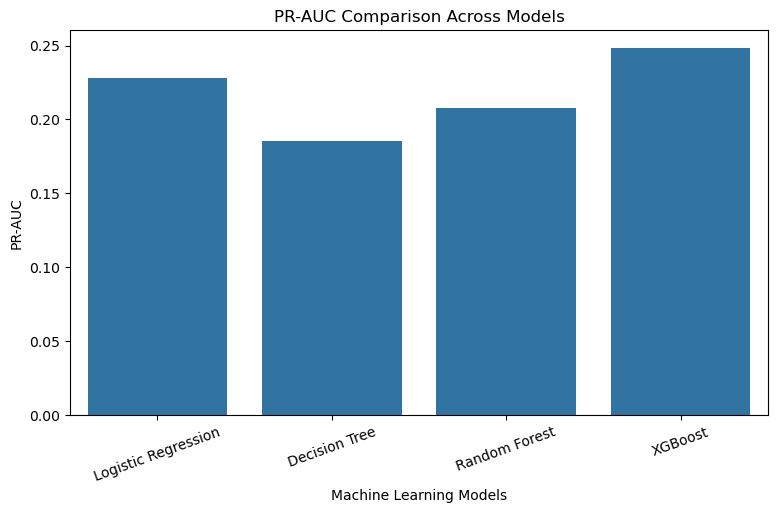

In [92]:
model_names = [
    'Logistic Regression',
    'Decision Tree',
    'Random Forest',
    'XGBoost'
]

pr_auc_scores = [
    0.2278,
    0.1857,
    0.2079,
    0.2481
]

plt.figure(figsize=(9, 5))

sns.barplot(
    x=model_names,
    y=pr_auc_scores
)

plt.title('PR-AUC Comparison Across Models')
plt.ylabel('PR-AUC')
plt.xlabel('Machine Learning Models')
plt.xticks(rotation=20)
plt.show()

In [93]:
feature_importance = pd.DataFrame({
    'Feature': preprocessor.get_feature_names_out(),
    'Importance': xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(15))

                                               Feature  Importance
28                                   num__EXT_SOURCE_3    0.047359
27                                   num__EXT_SOURCE_2    0.045511
119          cat__NAME_EDUCATION_TYPE_Higher education    0.021283
95                                  cat__CODE_GENDER_F    0.016798
117                      cat__NAME_INCOME_TYPE_Working    0.015576
26                                   num__EXT_SOURCE_1    0.015267
96                                  cat__CODE_GENDER_M    0.014646
122  cat__NAME_EDUCATION_TYPE_Secondary / secondary...    0.014171
63                                num__FLAG_DOCUMENT_3    0.014037
113                    cat__NAME_INCOME_TYPE_Pensioner    0.012568
99                                 cat__FLAG_OWN_CAR_Y    0.012028
98                                 cat__FLAG_OWN_CAR_N    0.011847
7                                   num__DAYS_EMPLOYED    0.011803
90                               num__EMPLOYMENT_YEARS    0.01

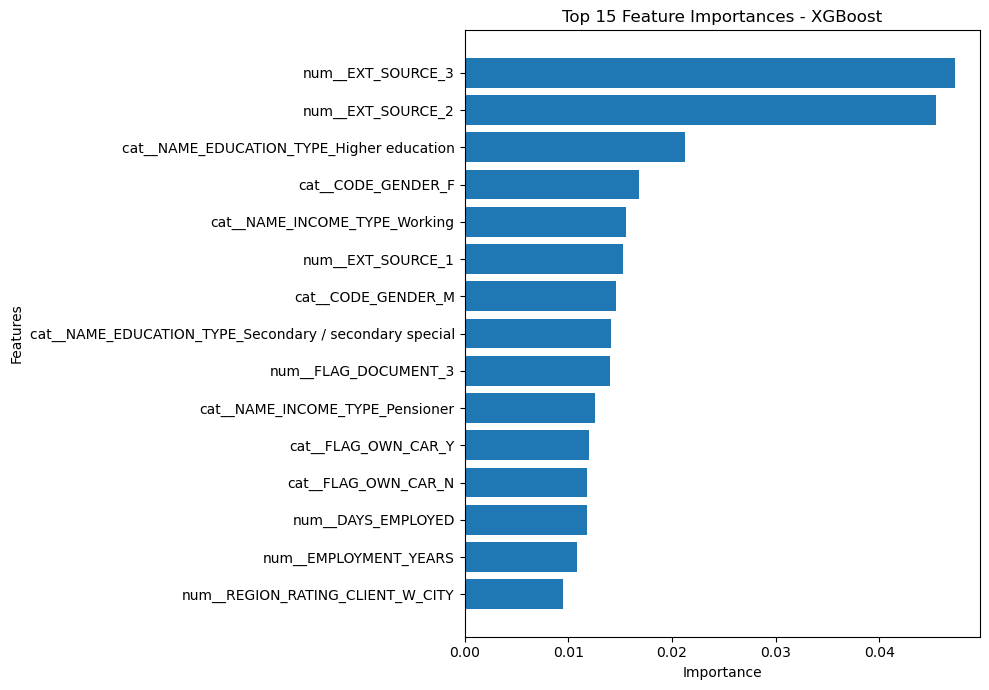

In [94]:
top_features = feature_importance.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.title('Top 15 Feature Importances - XGBoost')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [95]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

for threshold in thresholds:
    predictions = (xgb_pred_proba >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", precision_score(y_test, predictions))
    print("Recall:", recall_score(y_test, predictions))
    print("F1 Score:", f1_score(y_test, predictions))


Threshold: 0.2
Precision: 0.09303762039878781
Recall: 0.9707955689828801
F1 Score: 0.16980201507785528

Threshold: 0.3
Precision: 0.11151795944801475
Recall: 0.9017119838872105
F1 Score: 0.19848817361619117

Threshold: 0.4
Precision: 0.13690435496000547
Recall: 0.8066465256797583
F1 Score: 0.23408048160378736

Threshold: 0.5
Precision: 0.1692014254881293
Recall: 0.6789526686807653
F1 Score: 0.2708936033429765

Threshold: 0.6
Precision: 0.21283255086071987
Recall: 0.5204431017119839
F1 Score: 0.30211621653221093

Threshold: 0.7
Precision: 0.27830900855561147
Recall: 0.3341389728096677
F1 Score: 0.30367929708951125


In [96]:
best_threshold = 0.70

xgb_tuned_pred = (
    xgb_pred_proba >= best_threshold
).astype(int)

print("Selected threshold:", best_threshold)
print("Tuned precision:", precision_score(y_test, xgb_tuned_pred))
print("Tuned recall:", recall_score(y_test, xgb_tuned_pred))
print("Tuned F1-score:", f1_score(y_test, xgb_tuned_pred))

Selected threshold: 0.7
Tuned precision: 0.27830900855561147
Tuned recall: 0.3341389728096677
Tuned F1-score: 0.30367929708951125


Tuned Confusion Matrix:
[[52236  4302]
 [ 3306  1659]]


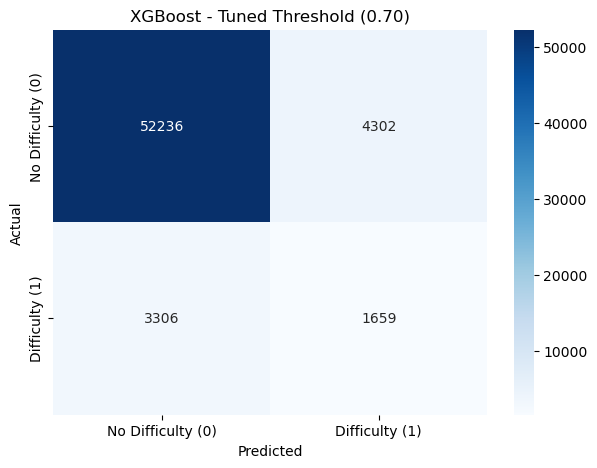

In [97]:
cm_tuned = confusion_matrix(y_test, xgb_tuned_pred)

print("Tuned Confusion Matrix:")
print(cm_tuned)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Difficulty (0)', 'Difficulty (1)'],
    yticklabels=['No Difficulty (0)', 'Difficulty (1)']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('XGBoost - Tuned Threshold (0.70)')
plt.show()

In [98]:
from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_train_sub.shape)
print("Validation set:", X_val.shape)

print("\nTraining target distribution:")
print(y_train_sub.value_counts(normalize=True) * 100)

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True) * 100)

Training subset: (196806, 108)
Validation set: (49202, 108)

Training target distribution:
TARGET
0    91.927075
1     8.072925
Name: proportion, dtype: float64

Validation target distribution:
TARGET
0    91.927157
1     8.072843
Name: proportion, dtype: float64


In [99]:
from sklearn.base import clone

validation_preprocessor = clone(preprocessor)

X_train_sub_processed = validation_preprocessor.fit_transform(X_train_sub)

X_val_processed = validation_preprocessor.transform(X_val)

print("Processed training subset:", X_train_sub_processed.shape)
print("Processed validation set:", X_val_processed.shape)

Processed training subset: (196806, 234)
Processed validation set: (49202, 234)


In [100]:
scale_pos_weight_val = (
    (y_train_sub == 0).sum() / (y_train_sub == 1).sum()
)

xgb_validation_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight_val,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb_validation_model.fit(
    X_train_sub_processed,
    y_train_sub
)

print("Validation model training completed!")

Validation model training completed!


In [101]:
y_val_proba = xgb_validation_model.predict_proba(
    X_val_processed
)[:, 1]

print("First 10 predicted probabilities:")
print(y_val_proba[:10])

First 10 predicted probabilities:
[0.45369625 0.18344277 0.14899476 0.22897002 0.6749231  0.41278058
 0.31716323 0.42251366 0.4495852  0.3377371 ]


In [102]:
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:
    val_predictions = (y_val_proba >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", precision_score(y_val, val_predictions))
    print("Recall:", recall_score(y_val, val_predictions))
    print("F1 Score:", f1_score(y_val, val_predictions))


Threshold: 0.2
Precision: 0.09354439292043992
Recall: 0.9700402819738168
F1 Score: 0.17063395407541906

Threshold: 0.3
Precision: 0.11210649960845732
Recall: 0.9010574018126888
F1 Score: 0.19940384990389168

Threshold: 0.4
Precision: 0.13630177766437016
Recall: 0.8068982880161127
F1 Score: 0.2332096339954886

Threshold: 0.5
Precision: 0.16631276542593054
Recall: 0.6704431017119838
F1 Score: 0.2665132105684548

Threshold: 0.6
Precision: 0.20607661822985468
Recall: 0.5105740181268882
F1 Score: 0.29363642945051766

Threshold: 0.7
Precision: 0.2613957240822912
Recall: 0.32628398791540786
F1 Score: 0.2902575587905935


In [103]:
best_threshold = 0.60

print("Selected validation threshold:", best_threshold)

Selected validation threshold: 0.6


In [104]:
final_xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

final_xgb_model.fit(
    X_train_processed,
    y_train
)

print("Final XGBoost model training completed!")

Final XGBoost model training completed!


In [105]:
final_test_proba = final_xgb_model.predict_proba(
    X_test_processed
)[:, 1]

final_test_pred = (
    final_test_proba >= best_threshold
).astype(int)

print("Final test predictions generated!")
print("Selected threshold:", best_threshold)

Final test predictions generated!
Selected threshold: 0.6


In [106]:
print("Final XGBoost Model Performance")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, final_test_pred))
print("Precision:", precision_score(y_test, final_test_pred))
print("Recall:", recall_score(y_test, final_test_pred))
print("F1 Score:", f1_score(y_test, final_test_pred))
print("ROC-AUC:", roc_auc_score(y_test, final_test_proba))
print("PR-AUC:", average_precision_score(y_test, final_test_proba))

Final XGBoost Model Performance
--------------------------------
Accuracy: 0.8058956473667951
Precision: 0.21283255086071987
Recall: 0.5204431017119839
F1 Score: 0.30211621653221093
ROC-AUC: 0.7584129391787294
PR-AUC: 0.24811010372649323


Final XGBoost Confusion Matrix:
[[46981  9557]
 [ 2381  2584]]


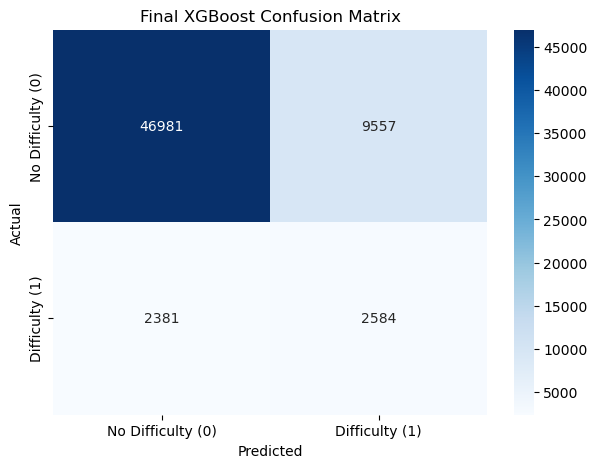

In [107]:
final_cm = confusion_matrix(y_test, final_test_pred)

print("Final XGBoost Confusion Matrix:")
print(final_cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Difficulty (0)', 'Difficulty (1)'],
    yticklabels=['No Difficulty (0)', 'Difficulty (1)']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Final XGBoost Confusion Matrix')
plt.show()

In [108]:
redundant_features = [
    ('DAYS_BIRTH', 'AGE'),
    ('DAYS_EMPLOYED', 'EMPLOYMENT_YEARS'),
    ('DAYS_ID_PUBLISH', 'ID_DOCUMENT_AGE_YEARS')
]

for original, engineered in redundant_features:
    print(f"{original} and {engineered}")

DAYS_BIRTH and AGE
DAYS_EMPLOYED and EMPLOYMENT_YEARS
DAYS_ID_PUBLISH and ID_DOCUMENT_AGE_YEARS


In [109]:
redundant_columns = [
    'DAYS_BIRTH',
    'DAYS_EMPLOYED',
    'DAYS_ID_PUBLISH'
]

X = X.drop(columns=redundant_columns)

print("Updated feature shape:", X.shape)

Updated feature shape: (307511, 105)


In [110]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (246008, 105)
Testing features: (61503, 105)


In [111]:
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include='object'
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 90
Categorical features: 15


In [112]:
#Rebuild the preprocessing pipeline

numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (246008, 231)
Processed testing data: (61503, 231)


In [113]:
#Create a validation set again

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_train_sub.shape)
print("Validation set:", X_val.shape)

Training subset: (196806, 105)
Validation set: (49202, 105)


In [114]:
# Preprocess the validation data

from sklearn.base import clone

validation_preprocessor = clone(preprocessor)

X_train_sub_processed = validation_preprocessor.fit_transform(
    X_train_sub
)

X_val_processed = validation_preprocessor.transform(X_val)

print("Processed training subset:", X_train_sub_processed.shape)
print("Processed validation set:", X_val_processed.shape)

Processed training subset: (196806, 231)
Processed validation set: (49202, 231)


In [115]:
# Calculate class imbalance ratio
scale_pos_weight = (
    (y_train_sub == 0).sum() /
    (y_train_sub == 1).sum()
)

print("Scale positive weight:", scale_pos_weight)

Scale positive weight: 11.387084592145015


In [116]:
# XGBoost hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

In [117]:
param_dist = {
    'n_estimators': randint(100, 400),
    'max_depth': randint(3, 8),
    'learning_rate': uniform(0.01, 0.19),
    'min_child_weight': randint(1, 10),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'gamma': uniform(0, 5)
}

In [118]:
xgb_tuning_model = xgb.XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    random_state=42,
    n_jobs=1
)

In [119]:
random_search = RandomizedSearchCV(
    estimator=xgb_tuning_model,
    param_distributions=param_dist,
    n_iter=15,
    scoring='average_precision',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

In [120]:
random_search.fit(
    X_train_sub_processed,
    y_train_sub
)

print("Hyperparameter tuning completed!")

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Hyperparameter tuning completed!


In [121]:
# Find the best parameters
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(random_search.best_score_)

Best Parameters:
{'colsample_bytree': np.float64(0.786705157299192), 'gamma': np.float64(4.299702033681603), 'learning_rate': np.float64(0.13925843233167814), 'max_depth': 3, 'min_child_weight': 7, 'n_estimators': 373, 'subsample': np.float64(0.9795542149013333)}

Best Cross-Validation PR-AUC:
0.23726793717566172


In [122]:
# Creating tuned XGBoost model
tuned_xgb_model = random_search.best_estimator_

print("Tuned XGBoost model created!")

Tuned XGBoost model created!


In [123]:
tuned_val_proba = tuned_xgb_model.predict_proba(
    X_val_processed
)[:, 1]

print("First 10 predicted probabilities:")
print(tuned_val_proba[:10])

First 10 predicted probabilities:
[0.6564911  0.166888   0.18037239 0.23556036 0.68942606 0.31548798
 0.2898542  0.4205418  0.48648652 0.32592443]


In [124]:
tuned_val_pred = (
    tuned_val_proba >= 0.50
).astype(int)

print("Tuned XGBoost Validation Performance")
print("------------------------------------")

print("Accuracy:", accuracy_score(y_val, tuned_val_pred))
print("Precision:", precision_score(y_val, tuned_val_pred))
print("Recall:", recall_score(y_val, tuned_val_pred))
print("F1 Score:", f1_score(y_val, tuned_val_pred))
print("ROC-AUC:", roc_auc_score(y_val, tuned_val_proba))
print("PR-AUC:", average_precision_score(y_val, tuned_val_proba))

Tuned XGBoost Validation Performance
------------------------------------
Accuracy: 0.7026137148896386
Precision: 0.1669582604348913
Recall: 0.6727089627391742
F1 Score: 0.2675210252302763
ROC-AUC: 0.7547450548711643
PR-AUC: 0.23752106816726498


In [125]:
original_val_pr_auc = average_precision_score(
    y_val,
    y_val_proba
)

tuned_val_pr_auc = average_precision_score(
    y_val,
    tuned_val_proba
)

print("Original Validation PR-AUC:", original_val_pr_auc)
print("Tuned Validation PR-AUC:", tuned_val_pr_auc)

Original Validation PR-AUC: 0.23592969939197433
Tuned Validation PR-AUC: 0.23752106816726498


In [126]:
tuned_best_threshold = 0.50

print("Tuned model threshold:", tuned_best_threshold)

Tuned model threshold: 0.5


In [127]:
# Generate final test predictions
final_tuned_xgb = random_search.best_estimator_

final_tuned_xgb.fit(
    X_train_processed,
    y_train
)

print("Final tuned XGBoost model training completed!")

Final tuned XGBoost model training completed!


In [128]:
final_tuned_proba = final_tuned_xgb.predict_proba(
    X_test_processed
)[:, 1]

final_tuned_pred = (
    final_tuned_proba >= tuned_best_threshold
).astype(int)

print("Final tuned test predictions generated!")

Final tuned test predictions generated!


In [129]:
# Evaluating the tuned model
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

print("Accuracy:", accuracy_score(y_test, final_tuned_pred))
print("Precision:", precision_score(y_test, final_tuned_pred))
print("Recall:", recall_score(y_test, final_tuned_pred))
print("F1-score:", f1_score(y_test, final_tuned_pred))
print("ROC-AUC:", roc_auc_score(y_test, final_tuned_proba))
print("PR-AUC:", average_precision_score(y_test, final_tuned_proba))

Accuracy: 0.7065183812171764
Precision: 0.17031997984378935
Recall: 0.6807653575025177
F1-score: 0.2724707779121322
ROC-AUC: 0.7605243816980992
PR-AUC: 0.252381900373742


In [131]:
!pip install shap

import shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 544.4/544.4 kB 7.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [shap]━━━━━━ 1/2 [shap]


In [132]:
explainer = shap.TreeExplainer(final_tuned_xgb)

X_shap = X_test_processed[:500]

shap_values = explainer.shap_values(X_shap)

print("SHAP values generated:", np.array(shap_values).shape)

SHAP values generated: (500, 231)


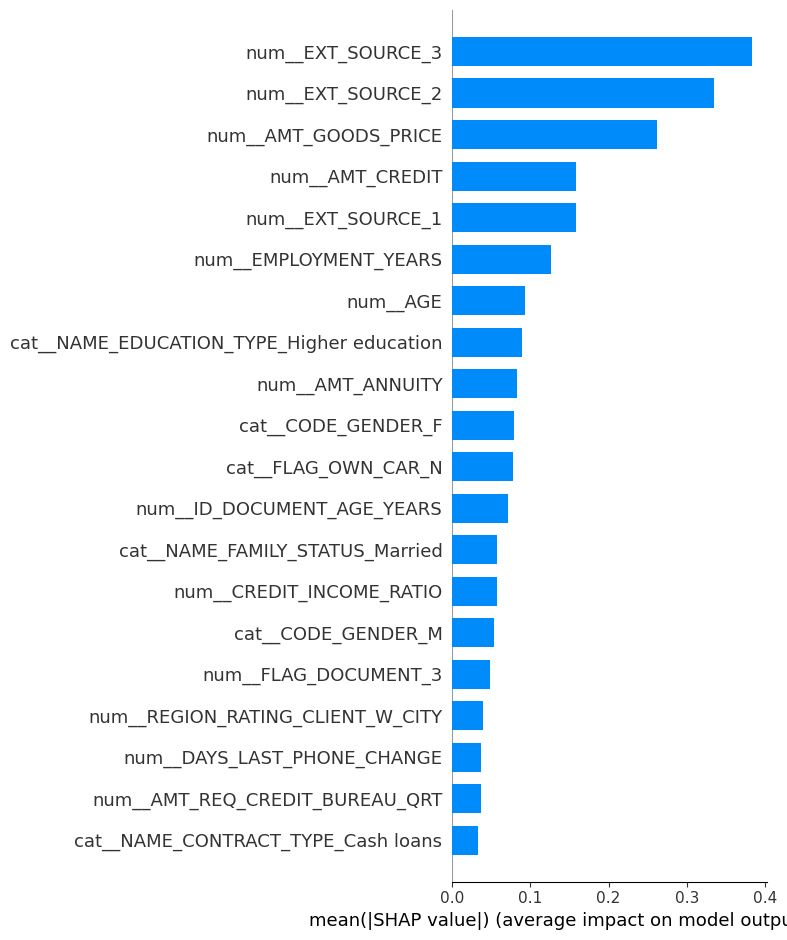

In [133]:
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=preprocessor.get_feature_names_out(),
    plot_type="bar"
)

## Final Conclusion

In this project, I built a machine learning model to predict whether loan applicants may face payment difficulties.

After performing data cleaning, EDA, feature engineering and model training, I used XGBoost to achieve:

- Accuracy: **70.65%**
- Precision: **17.03%**
- Recall: **68.08%**
- F1-score: **27.25%**
- ROC-AUC: **76.05%**
- PR-AUC: **25.24%**

SHAP analysis showed that EXT_SOURCE_1, employment duration, age, education and annuity amount were among the most important features.

The model can identify many applicants who may face payment difficulties, but it also produces several incorrect high-risk predictions. Therefore, it can support risk assessment but should not be used as the only basis for lending decisions.

## Business Recommendations

1. Use the model to help identify potentially high-risk applicants.
2. Review high-risk predictions carefully before making decisions.
3. Improve precision to reduce incorrect risk predictions.
4. Monitor and improve model performance regularly.

## Limitations

- The dataset contains missing values and imbalanced classes.
- The model makes both false-positive and false-negative predictions.
- Feature importance does not prove cause and effect.
- Human review is still important in lending decisions.